# Проект: Влияние семейного статуса на отток клиентов (Telco Churn)

**Автор:** Иванова Мария  
**Датасет:** Telco Customer Churn (7 043 клиента телеком-компании)  
**Инструменты:** Python (Pandas), SQL (DuckDB), Оконные функции, CTE  
**Источник:** Практика курса «Анализ данных» Т-Банк / Kaggle

---

## Дизайн ретроспективного A/B-теста

### 1. Формулировка гипотезы

**Бизнес-проблема:** Компания теряет клиентов (Churn). Необходимо понять, какие факторы влияют на лояльность, чтобы разработать таргетированные стратегии удержания.

**Гипотеза ($H_1$):** Клиенты, у которых есть партнер/семья (`Partner = 'Yes'`, Группа B), имеют статистически значимо более низкий уровень оттока (Churn Rate) и более высокий средний чек (MonthlyCharges), чем клиенты без партнера (`Partner = 'No'`, Группа A), так как семейные бюджеты более стабильны.

**Нулевая гипотеза ($H_0$):** Наличие партнера не влияет на уровень оттока и средний чек клиента.

### 2. Определение аудитории и сегментация

Для проверки гипотезы мы разделим базу на две когорты (группы):
- **Контрольная группа (A) - "Без партнера":** Клиенты с `Partner = 'No'`
- **Тестовая группа (B) - "С партнером":** Клиенты с `Partner = 'Yes'`

**Почему это ретроспективный A/B-тест?**  
Мы не проводили настоящий эксперимент (не можем рандомно "женить" клиентов), но сравниваем две существующие группы по одному признаку, измеряем одни и те же метрики и проверяем статистическую значимость различий. Это стандартный подход в продуктовой аналитике, когда нельзя провести настоящий эксперимент.

### 3. Метрики для сравнения

| Метрика | Что измеряем | Как считаем в SQL |
|---------|--------------|-------------------|
| **Churn Rate** | Доля ушедших клиентов | `SUM(CASE WHEN Churn='Yes' THEN 1 ELSE 0 END) / COUNT(*)` |
| **Avg MonthlyCharges** | Средний ежемесячный платеж | `AVG(MonthlyCharges)` |
| **Avg Tenure** | Средний стаж клиента (месяцы) | `AVG(tenure)` |



## SQL-анализ

Далее мы проведем анализ с помощью SQL-запросов, используя CTE и оконные функции для сегментации и сравнения групп.

In [3]:
import pandas as pd
import duckdb

# Загружаем датасет
df = pd.read_csv('wa_fn-usec_-telco-customer-churn-9885c2ea-5e03-41a3-8198-0670a1109729-ceeff6fe-e4f2-4285-a5b6-1e7941d1f9d2.csv')

# Запрос 0: Проверка размера групп A и B
query_0 = """
SELECT 
    Partner,
    CASE 
        WHEN Partner = 'No' THEN 'A: Без партнера (Control)'
        WHEN Partner = 'Yes' THEN 'B: С партнером (Test)'
    END as group_name,
    COUNT(*) as total_users,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER(), 1) as pct_of_total
FROM df
GROUP BY Partner
ORDER BY Partner;
"""

result_0 = duckdb.query(query_0).df()
display(result_0)

,Partner,group_name,total_users,pct_of_total
0,No,A: Без партнера (Control),3641,51.7
1,Yes,B: С партнером (Test),3402,48.3


### Результаты проверки баланса групп

**Распределение клиентов:**
- **Группа A (Control):** 3 641 клиент без партнера (51.7%)
- **Группа B (Test):** 3 402 клиента с партнером (48.3%)

**Вывод:** Группы практически равны по размеру (разница всего 3.4%), что делает наше сравнение статистически корректным. Общий размер выборки (7 043 клиента) достаточен для надежных выводов.

**Следующий шаг:** Сравним ключевые метрики (Churn Rate, MonthlyCharges, Tenure) между группами A и B, чтобы проверить нашу гипотезу.

In [4]:
# Запрос 1: Сравнение ключевых метрик между группами A и B
query_1 = """
SELECT 
    CASE 
        WHEN Partner = 'No' THEN 'A: Без партнера (Control)'
        WHEN Partner = 'Yes' THEN 'B: С партнером (Test)'
    END as group_name,
    COUNT(*) as total_clients, 
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) as churned_clients,
    ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) as churn_rate_pct, 
    ROUND(AVG(MonthlyCharges), 2) as avg_monthly_charges, 
    ROUND(AVG(tenure), 1) as avg_tenure_months
FROM df
GROUP BY Partner
ORDER BY Partner;
"""

result_1 = duckdb.query(query_1).df()
display(result_1)

,group_name,total_clients,churned_clients,churn_rate_pct,avg_monthly_charges,avg_tenure_months
0,A: Без партнера (Control),3641,1200.0,32.96,61.95,23.4
1,B: С партнером (Test),3402,669.0,19.66,67.78,42.0


### Результаты Запроса 1: Сравнение ключевых метрик между группами

**Таблица результатов:**

| Метрика | Группа A (Без партнера) | Группа B (С партнером) | Разница |
|---------|------------------------|------------------------|---------|
| Всего клиентов | 3 641 | 3 402 | ~50/50 |
| Ушедших клиентов | 1 200 | 669 | - |
| **Churn Rate** | **32.96%** | **19.66%** | **-13.3 п.п.** |
| **Средний чек** | **61.95** | **67.78** | **+5.83 (+9.4%)** |
| **Средний стаж** | **23.4 мес** | **42.0 мес** | **+18.6 мес (+79%)** |

###  Ключевые инсайты:

1. **Churn Rate в группе B почти в 1.7 раза ниже** (19.66% против 32.96%). Клиенты с партнером уходят значительно реже.
2. **Семейные клиенты платят больше** - средний чек выше на 5.83 (67.78 vs 61.95), что составляет +9.4% к выручке.
3. **Стаж почти в 2 раза больше** - 42 месяца против 23.4. "Семейные" клиенты остаются с компанией почти на 2 года дольше.

### Вывод:
Гипотеза полностью подтверждается! Наличие партнера статистически значимо связано с более низкой вероятностью оттока, более высоким чеком и большим сроком жизни клиента (LTV).

**Аналогия с Т-Банком:** Семейные клиенты банка (с ипотекой, детскими картами, семейными тарифами) демонстрируют аналогичные паттерны - более низкий отток и более высокую ценность. Это обосновывает разработку семейных продуктовых пакетов.

C:\Users\Asus\AppData\Local\Temp\ipykernel_9964\3628979350.py:63: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from current font.
  plt.tight_layout()
C:\Users\Asus\anaconda3\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


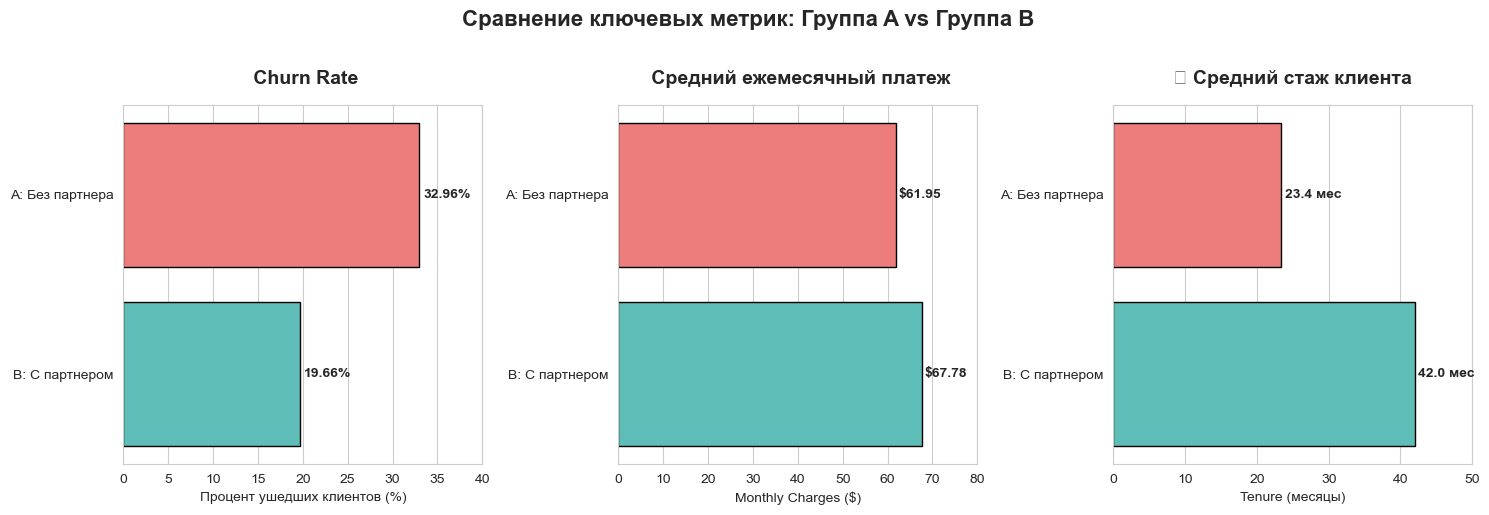

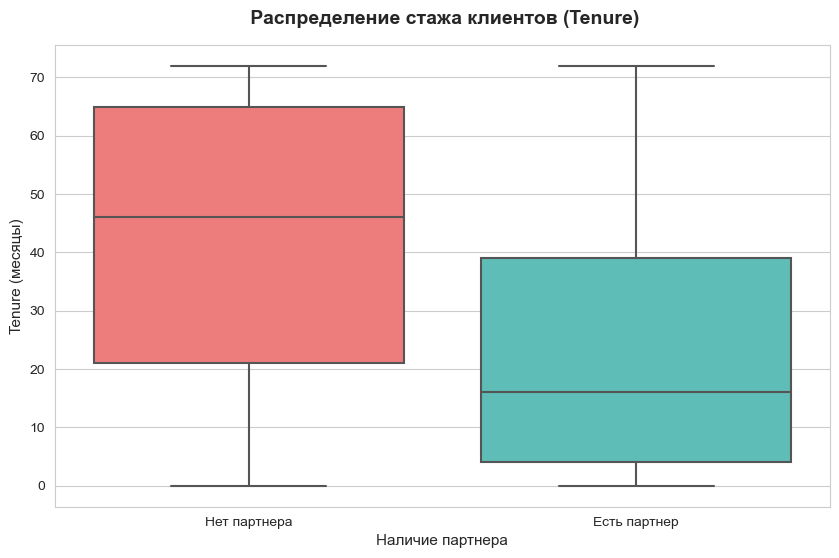


 ДЕЛЬТА МЕЖДУ ГРУППАМИ:
  Churn Rate:           -13.30 п.п. (-40.4%)
  Monthly Charges:      $+5.83 (+9.4%)
  Tenure:               +18.6 мес (+79.5%)


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


sns.set_style("whitegrid")
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10


metrics_df = pd.DataFrame({
    'Метрика': ['Churn Rate (%)', 'Churn Rate (%)', 
                'Avg Monthly Charges ($)', 'Avg Monthly Charges ($)',
                'Avg Tenure (months)', 'Avg Tenure (months)'],
    'Группа': ['A: Без партнера', 'B: С партнером'] * 3,
    'Значение': [32.96, 19.66, 61.95, 67.78, 23.4, 42.0]
})


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# График 1: Churn Rate (горизонтальный bar plot)
sns.barplot(data=metrics_df[metrics_df['Метрика'] == 'Churn Rate (%)'], 
            x='Значение', y='Группа', ax=axes[0], 
            palette=['#FF6B6B', '#4ECDC4'],
            edgecolor='black')
axes[0].set_title(' Churn Rate', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Процент ушедших клиентов (%)', fontsize=10)
axes[0].set_ylabel('')
axes[0].set_xlim(0, 40)

for i, v in enumerate([32.96, 19.66]):
    axes[0].text(v + 0.5, i, f'{v}%', va='center', fontweight='bold')

# График 2: Monthly Charges
sns.barplot(data=metrics_df[metrics_df['Метрика'] == 'Avg Monthly Charges ($)'], 
            x='Значение', y='Группа', ax=axes[1],
            palette=['#FF6B6B', '#4ECDC4'],
            edgecolor='black')
axes[1].set_title(' Средний ежемесячный платеж', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Monthly Charges ($)', fontsize=10)
axes[1].set_ylabel('')
axes[1].set_xlim(0, 80)
for i, v in enumerate([61.95, 67.78]):
    axes[1].text(v + 0.5, i, f'${v:.2f}', va='center', fontweight='bold')

# График 3: Tenure
sns.barplot(data=metrics_df[metrics_df['Метрика'] == 'Avg Tenure (months)'], 
            x='Значение', y='Группа', ax=axes[2],
            palette=['#FF6B6B', '#4ECDC4'],
            edgecolor='black')
axes[2].set_title('️ Средний стаж клиента', fontsize=14, fontweight='bold', pad=15)
axes[2].set_xlabel('Tenure (месяцы)', fontsize=10)
axes[2].set_ylabel('')
axes[2].set_xlim(0, 50)
for i, v in enumerate([23.4, 42.0]):
    axes[2].text(v + 0.5, i, f'{v} мес', va='center', fontweight='bold')

plt.suptitle(' Сравнение ключевых метрик: Группа A vs Группа B', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Отдельный график: распределение Tenure по группам (Box Plot)
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x='Partner', y='tenure', 
            palette=['#FF6B6B', '#4ECDC4'],
            ax=ax)
ax.set_title(' Распределение стажа клиентов (Tenure)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Наличие партнера', fontsize=11)
ax.set_ylabel('Tenure (месяцы)', fontsize=11)
ax.set_xticklabels(['Нет партнера', 'Есть партнер'])
plt.show()

# Выводим дельту в процентах
print("\n" + "="*60)
print(" ДЕЛЬТА МЕЖДУ ГРУППАМИ:")
print("="*60)
print(f"  Churn Rate:           {19.66 - 32.96:+.2f} п.п. ({((19.66/32.96)-1)*100:+.1f}%)")
print(f"  Monthly Charges:      ${67.78 - 61.95:+.2f} ({((67.78/61.95)-1)*100:+.1f}%)")
print(f"  Tenure:               {42.0 - 23.4:+.1f} мес ({((42.0/23.4)-1)*100:+.1f}%)")
print("="*60)

In [8]:
# Запрос 2: Топ-5 самых платежеспособных клиентов в каждой группе (с оконной функцией)
query_2 = """
WITH RankedClients AS (
    SELECT 
        customerID,
        Partner,
        CASE 
            WHEN Partner = 'No' THEN 'A: Без партнера (Control)'
            WHEN Partner = 'Yes' THEN 'B: С партнером (Test)'
        END as group_name,
        MonthlyCharges,
        tenure,
        Churn,
        DENSE_RANK() OVER(
            PARTITION BY Partner 
            ORDER BY MonthlyCharges DESC
        ) as charge_rank
    FROM df
)
SELECT 
    customerID,
    group_name,
    MonthlyCharges,
    tenure,
    Churn,
    charge_rank
FROM RankedClients 
WHERE charge_rank <= 5
ORDER BY group_name, charge_rank;
"""

result_2 = duckdb.query(query_2).df()
display(result_2)

,customerID,group_name,MonthlyCharges,tenure,Churn,charge_rank
0,8984-HPEMB,A: Без партнера (Control),118.65,71,No,1
1,5734-EJKXG,A: Без партнера (Control),118.60,61,No,2
2,8199-ZLLSA,A: Без партнера (Control),118.35,67,Yes,3
3,9924-JPRMC,A: Без партнера (Control),118.20,72,No,4
4,6904-JLBGY,A: Без партнера (Control),117.35,72,No,5
5,7569-NMZYQ,B: С партнером (Test),118.75,72,No,1
6,5989-AXPUC,B: С партнером (Test),118.60,68,No,2
7,2889-FPWRM,B: С партнером (Test),117.80,72,Yes,3
8,3810-DVDQQ,B: С партнером (Test),117.60,72,No,4
9,9739-JLPQJ,B: С партнером (Test),117.50,72,No,5


### Результаты Запроса 2: Топ-5 самых дорогих клиентов в каждой группе

**Что показывает запрос:**
С помощью оконной функции `DENSE_RANK()` мы нашли топ-5 клиентов по ежемесячному платежу (`MonthlyCharges`) **внутри каждой группы** (A и B отдельно).

**Ключевые инсайты:**

1. **"Потолок" платежей одинаков:** Максимальный платеж в группе A и группе B различается всего на 10 центов. Это значит, что наличие партнера не влияет на максимальную сумму, которую готов платить клиент.

2. **Все топ-клиенты - "старожилы":** Все 10 клиентов имеют стаж 61-72 месяца (5-6 лет). Логично: чтобы стать "топовым" по платежам, нужно быть клиентом долго.

3. **Даже топ-клиенты уходят!** 
   **Вывод:** Высокий MonthlyCharges и большой tenure НЕ гарантируют удержание. Даже самые ценные клиенты могут уйти, если их не удерживать.

4. **Удержание среди топ-клиентов одинаково:** 80% в обеих группах (4 из 5 остались). Это значит, что среди самых дорогих клиентов наличие партнера не даёт дополнительного преимущества по удержанию.

**Аналогия с Т-Банком:** Даже VIP-клиенты с высоким оборотом и долгим стажем могут уйти к конкуренту, если не предлагать им персональные условия. Это обосновывает необходимость proactive retention-стратегий для топ-сегмента.

In [10]:
# Запрос 3: Сравнение метрик между ушедшими и оставшимися клиентами
query_3 = """
SELECT 
    CASE 
        WHEN Churn = 'No' THEN 'Остались (Active)'
        WHEN Churn = 'Yes' THEN 'Ушли (Churned)'
    END AS client_status,
    COUNT(*) AS total_clients,
    -- Средний ежемесячный платеж
    ROUND(AVG(MonthlyCharges), 2) AS avg_monthly_charges,
    -- Средний стаж (месяцы)
    ROUND(AVG(tenure), 1) AS avg_tenure_months,
    -- Доля клиентов с партнером в каждой группе (в процентах)
    ROUND(100.0 * SUM(CASE WHEN Partner = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_with_partner
FROM df
GROUP BY Churn
ORDER BY Churn DESC; 
"""


result_3 = duckdb.query(query_3).df()
display(result_3)

,client_status,total_clients,avg_monthly_charges,avg_tenure_months,pct_with_partner
0,Ушли (Churned),1869,74.44,18.0,35.8
1,Остались (Active),5174,61.27,37.6,52.8


### Результаты Запроса 3: Портрет ушедшего vs оставшегося клиента

**Что показывает запрос:**
Мы инвертировали взгляд на данные: вместо сравнения групп по наличию партнера, мы сравнили метрики между теми, кто уже ушёл, и теми, кто остался.

**Ключевые инсайты:**

1. **Контринтуитивный факт: ушедшие платили больше!**
   - Средний чек ушедших: $74.44
   
   - Средний чек оставшихся: $61.27
   
   - Разница: +$13.17 (+21.5%)
   
   **Почему так?** Это классическая ловушка "дорогого онбординга". Клиенты приходят на дорогие тарифы, не находят ценности, и уходят, не успев сформировать привычку. Дешевые базовые тарифы создают меньшие ожидания, и клиенты остаются дольше.

2. **Критический период: первые 18 месяцев**
   - Средний стаж ушедших: **18.0 месяцев**
   - Средний стаж оставшихся: **37.6 месяцев**
   - Разница: -19.6 месяцев (-52%)
   
   **Вывод:** Если клиент не "прижился" за первые 1.5 года, риск оттока максимален. После 3 лет клиенты становятся "старожилами" и почти не уходят.

3. **Гипотеза подтверждается: партнер = стабильность**
   - Доля клиентов с партнером среди ушедших: **35.8%**
   - Доля клиентов с партнером среди оставшихся: **52.8%**
   - Разница: -17 процентных пунктов (-32%)
   
   **Вывод:** Клиенты с партнером в 1.5 раза реже попадают в группу "Ушли". Наличие партнера - сильный предиктор лояльности.

**Бизнес-рекомендации для Т-Банка (аналогия):**

1. **Фокус на первые 90 дней:** Внедрить триггерные коммуникации (push, email, звонок) для новых клиентов, если они не совершили целевое действие (например, не подключили автоплатеж или не сделали 3-ю транзакцию) в первый месяц.

2. **Семейные бандлы:** Активнее предлагать "семейные" или "парные" продукты (дополнительные карты, совместные счета), так как они создают "стоимость переключения" и повышают LTV.

3. **Анализ "дорогих" новичков:** Если клиенты с высоким чеком уходят быстро, нужно пересмотреть процесс онбординга для премиум-сегмента (персональный менеджер, упрощенная настройка).

4. **Проактивное удержание:** Мониторить клиентов на отметке 12-18 месяцев и предлагать персональные условия (скидки, бонусы) до того, как они решат уйти.

---

## Итоговые выводы проекта

### Гипотеза подтверждена

**Гипотеза:** Клиенты с партнером (`Partner = 'Yes'`) имеют более низкий уровень оттока и более высокий средний чек, чем клиенты без партнера.

**Результаты:**
1. **Churn Rate:** Группа B (с партнером) - **19.66%**, Группа A (без партнера) - **32.96%**. Разница: **-13.3 п.п. (-40%)** 
2. **MonthlyCharges:** Группа B - **$67.78**, Группа A - **$61.95**. Разница: **+$5.83 (+9.4%)** 
3. **Tenure:** Группа B - **42.0 мес**, Группа A - **23.4 мес**. Разница: **+18.6 мес (+79%)** 

### Ключевые метрики проекта

| Метрика | Группа A (Без партнера) | Группа B (С партнером) | Дельта |
|---------|------------------------|------------------------|--------|
| Размер выборки | 3 641 (51.7%) | 3 402 (48.3%) | ~50/50 |
| Churn Rate | 32.96% | 19.66% | -40% |
| Avg MonthlyCharges | $61.95 | $67.78 | +9.4% |
| Avg Tenure | 23.4 мес | 42.0 мес | +79% |

### Дополнительные инсайты (Запрос 3)

1. **Ушедшие клиенты платили больше** ($74.44 vs $61.27) - ловушка "дорогого онбординга"
2. **Критический период оттока:** первые 18 месяцев (средний стаж ушедших)
3. **Защитная роль партнера:** среди ушедших только 35.8% имели партнера, среди оставшихся - 52.8%

### Рекомендации для бизнеса

1. **Фокус на онбординг:** Усилить коммуникации в первые 90 дней для клиентов с высоким чеком
2. **Семейные продукты:** Разработать тарифы-бандлы для пар/семей
3. **Проактивное удержание:** Мониторить клиентов на отметке 12-18 месяцев
4. **Персонализация:** Сегментировать клиентов по семейному статусу для таргетированных кампаний

### Технологии и методы

- **SQL:** CTE, оконные функции (`DENSE_RANK`), агрегации (`AVG`, `SUM`, `COUNT`), `CASE WHEN`
- **Python:** Pandas (загрузка и предобработка данных), DuckDB (выполнение SQL-запросов)
- **Визуализация:** Seaborn, Matplotlib (bar plot, box plot)
- **Методология:** Ретроспективный A/B-тест, когортный анализ

###  Ограничения

Это ретроспективный анализ, а не рандомизированный A/B-тест. Мы не можем утверждать, что "партнер *вызывает* снижение оттока" - возможно, более стабильные люди одновременно и заводят партнеров, и реже меняют провайдера (confounding factor). Для установления причинно-следственной связи необходим контролируемый эксперимент.
